# Homework 4: Evaluation Metrics for Classification

## Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

## Data preparation

In [4]:
df = pd.read_csv('data/course_lead_scoring_2026.csv')
missing = df.isnull().sum()
missing[missing > 0]

lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64

In [5]:
categorical = list(df.select_dtypes(exclude='number').columns)
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

print('categorical:', categorical)
print('numerical:', numerical)

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


np.int64(0)

## Split the data

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.pop('converted').values
y_val = df_val.pop('converted').values
y_test = df_test.pop('converted').values

print(len(df_train), len(df_val), len(df_test))

3000 1000 1000


## Q1. ROC AUC feature importance

In [7]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(col, round(auc, 4))

annual_income 0.6082
number_of_courses_viewed 0.723
interaction_count 0.7649
lead_score 0.7882


## Q2. Training the model

In [8]:
features = categorical + numerical

def train(df, y, C=1.0):
    dicts = df[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(df, dv, model):
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [9]:
dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)

auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

0.732

## Q3. Precision and recall

In [10]:
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    scores.append((t, tp, fp, fn, precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])
df_scores

,threshold,tp,fp,fn,precision,recall
0,0.00,586,414,0,0.586,1.000000
1,0.01,586,414,0,0.586,1.000000
2,0.02,586,414,0,0.586,1.000000
3,0.03,586,414,0,0.586,1.000000
4,0.04,586,414,0,0.586,1.000000
...,...,...,...,...,...,...
96,0.96,1,0,585,1.000,0.001706
97,0.97,0,0,586,0.000,0.000000
98,0.98,0,0,586,0.000,0.000000
99,0.99,0,0,586,0.000,0.000000


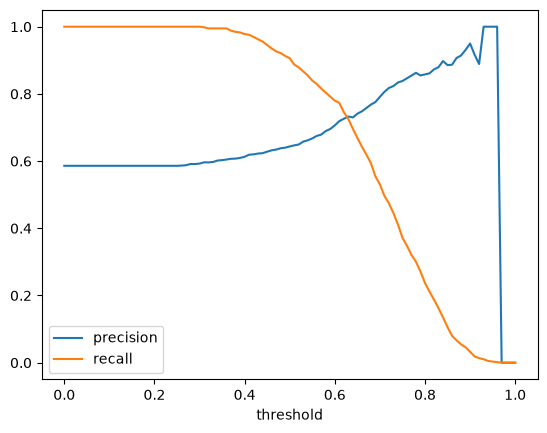

In [11]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [12]:
mask = ~((df_scores.precision == 0) & (df_scores.recall == 0))
df_valid = df_scores[mask].copy()
df_valid['diff'] = (df_valid.precision - df_valid.recall).abs()

best = df_valid.loc[df_valid['diff'].idxmin()]
print(round(best.threshold, 2), round(best.precision, 3), round(best.recall, 3))

0.63 0.733 0.725


## Q4. F1 score

In [13]:
p = df_scores.precision
r = df_scores.recall
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r), 0.0)

best = df_scores.loc[df_scores.f1.idxmax()]
print(round(best.threshold, 2), round(best.f1, 3))

0.41 0.758


## Q5. 5-Fold CV

In [14]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_vl = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_vl = df_vl.converted.values

    dv, model = train(df_tr, y_tr, C=1.0)
    y_pred_cv = predict(df_vl, dv, model)

    scores.append(roc_auc_score(y_vl, y_pred_cv))

print('mean: %.3f, std: %.3f' % (np.mean(scores), np.std(scores)))

mean: 0.732, std: 0.007


## Q6. Hyperparameter tuning

In [15]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_vl = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_vl = df_vl.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred_cv = predict(df_vl, dv, model)

        scores.append(roc_auc_score(y_vl, y_pred_cv))

    print('C=%s mean: %.3f, std: %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 mean: 0.617, std: 0.019
C=0.001 mean: 0.749, std: 0.010
C=1 mean: 0.732, std: 0.007
